In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
data_dir = Path("/Users/eyeremy/Documents/GTvate_stuff/CSV_reynoldstep/") # CHANGE TO LOAD IN CSV DATA


## READ CSV
# data = {}
# for file in data_dir.glob("*.csv"):
#     data[file.stem] = pd.read_csv(file)



## READ EXCEL
data = {}

for file in data_dir.glob("*.xlsx"):
    if file.name.startswith("~$"):
        continue 

    data[file.stem] = pd.read_excel(
        file,
        sheet_name="Samples"
    )


print(data.keys())


/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/s

dict_keys(['UUS1214_1', 'DS1212_1', 'DDS1212_1', 'US1212_2', 'US1207_1', 'UUS1213_2', 'US1214_2', 'US1211_1', 'DS1214_1', 'UUS1212_1', 'DS1213_2', 'US1213_1', 'DDS1213_2', 'US1213_2', 'DDS1213_1', 'DS1213_1', 'UUS1207_1', 'DS1214_2', 'DS1211_1', 'UUS1212_2', 'US1214_1', 'DDS1211_1', 'UUS1213_1', 'DS1207_1', 'DDS1207_1', 'DDS1212_2', 'US1212_1', 'UUS1214_2', 'UUS1211_1', 'DS1212_2'])


In [ ]:
# Extract frequencies per file
def get_freq(col):
    if isinstance(col, str) and "ǀf" in col:
        return col.split("ǀ")[1]
    return None

freq_sets = {}

for name, df in data.items():
    freqs = {
        get_freq(c)
        for c in df.columns
        if get_freq(c) is not None
    }
    freq_sets[name] = freqs

# Get full set of all frequencies across files
all_freqs = set.union(*freq_sets.values())

print(f"\nTotal unique frequencies across all files: {len(all_freqs)}")


# Check each file
for name, freqs in freq_sets.items():
    missing = all_freqs - freqs
    extra   = freqs - all_freqs

    print(f"\n{name}:")
    print(f"  num freqs = {len(freqs)}")

    if missing:
        print(f"  MISSING ({len(missing)}): {sorted(missing)}")
    else:
        print("  MISSING: None")

    if extra:
        print(f"  EXTRA: {sorted(extra)}")


Total unique frequencies across all files: 27

UUS1214_1:
  num freqs = 27
  MISSING: None

DS1212_1:
  num freqs = 27
  MISSING: None

DDS1212_1:
  num freqs = 27
  MISSING: None

US1212_2:
  num freqs = 27
  MISSING: None

US1207_1:
  num freqs = 27
  MISSING: None

UUS1213_2:
  num freqs = 27
  MISSING: None

US1214_2:
  num freqs = 27
  MISSING: None

US1211_1:
  num freqs = 27
  MISSING: None

DS1214_1:
  num freqs = 27
  MISSING: None

UUS1212_1:
  num freqs = 27
  MISSING: None

DS1213_2:
  num freqs = 27
  MISSING: None

US1213_1:
  num freqs = 27
  MISSING: None

DDS1213_2:
  num freqs = 27
  MISSING: None

US1213_2:
  num freqs = 27
  MISSING: None

DDS1213_1:
  num freqs = 27
  MISSING: None

DS1213_1:
  num freqs = 27
  MISSING: None

UUS1207_1:
  num freqs = 27
  MISSING: None

DS1214_2:
  num freqs = 27
  MISSING: None

DS1211_1:
  num freqs = 27
  MISSING: None

UUS1212_2:
  num freqs = 27
  MISSING: None

US1214_1:
  num freqs = 27
  MISSING: None

DDS1211_1:
  num fre

In [4]:
# GET FREQUENCIY COLUMNS FROM FILE

def get_freq(col):
    if "ǀf" in col:
        return col.split("ǀ")[1] 
    return None

freq_sets = []

for df in data.values():

    freqs = {
        get_freq(c)
        for c in df.columns
        if get_freq(c) is not None
    }

    freq_sets.append(freqs)

common_freqs = sorted(
    set.intersection(*freq_sets),
    key=lambda x: float(x[1:].replace("_","."))
)

print("Common freqs:", common_freqs)
print("Amount of freqs:", len(common_freqs))

Common freqs: ['f25', 'f31_5', 'f40', 'f50', 'f63', 'f80', 'f100', 'f125', 'f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000', 'f1250', 'f1600', 'f2000', 'f2500', 'f3100', 'f4000', 'f5000', 'f6300', 'f8000', 'f10000']
Amount of freqs: 27


In [5]:
for name, df in data.items():

    non_freq = [c for c in df.columns if "ǀf" not in c]

    freq_cols = [
        c for c in df.columns
        if get_freq(c) in common_freqs
    ]

    df = df[non_freq + freq_cols]

    data[name] = df

In [6]:
# SEPARATE EXPERIMENTS AND SENSORS

import re
from collections import defaultdict

grouped = defaultdict(list)

pattern = re.compile(r"([A-Z]+)(\d+)_(\d+)")

for name, df in data.items():

    m = pattern.match(name)

    probe = m.group(1)
    iteration = f"{m.group(2)}_{m.group(3)}"

    grouped[iteration].append((probe, df))

print(grouped.keys())

for k, v in grouped.items():
    print(k, [p for p,_ in v])

dict_keys(['1214_1', '1212_1', '1212_2', '1207_1', '1213_2', '1214_2', '1211_1', '1213_1'])
1214_1 ['UUS', 'DS', 'US']
1212_1 ['DS', 'DDS', 'UUS', 'US']
1212_2 ['US', 'UUS', 'DDS', 'DS']
1207_1 ['US', 'UUS', 'DS', 'DDS']
1213_2 ['UUS', 'DS', 'DDS', 'US']
1214_2 ['US', 'DS', 'UUS']
1211_1 ['US', 'DS', 'DDS', 'UUS']
1213_1 ['US', 'DDS', 'DS', 'UUS']


In [7]:
# GET RE NUMBER COLUMN

sample_df = next(iter(data.values()))

print("Columns in dataset:")
print(sample_df.columns)

re_col = next(
    c for c in sample_df.columns
    if "Re" in c or "re" in c
)

print("Using Reynolds column:", re_col)

Columns in dataset:
Index(['Date-Time', 'Reynolds_step', 'Leak Event', 'AC01-1400361ǀf100',
       'AC01-1400361ǀf1000', 'AC01-1400361ǀf10000', 'AC01-1400361ǀf125',
       'AC01-1400361ǀf1250', 'AC01-1400361ǀf160', 'AC01-1400361ǀf1600',
       'AC01-1400361ǀf200', 'AC01-1400361ǀf2000', 'AC01-1400361ǀf25',
       'AC01-1400361ǀf250', 'AC01-1400361ǀf2500', 'AC01-1400361ǀf3100',
       'AC01-1400361ǀf315', 'AC01-1400361ǀf31_5', 'AC01-1400361ǀf40',
       'AC01-1400361ǀf400', 'AC01-1400361ǀf4000', 'AC01-1400361ǀf50',
       'AC01-1400361ǀf500', 'AC01-1400361ǀf5000', 'AC01-1400361ǀf63',
       'AC01-1400361ǀf630', 'AC01-1400361ǀf6300', 'AC01-1400361ǀf80',
       'AC01-1400361ǀf800', 'AC01-1400361ǀf8000'],
      dtype='object')
Using Reynolds column: Reynolds_step


In [8]:
# SORT FREQUENCIES IN ORDER

sample_df = next(iter(data.values()))

freq_cols = [
    c for c in sample_df.columns
    if "ǀf" in c
]

freq_cols = sorted(
    freq_cols,
    key=lambda x: float(x.split("ǀf")[1].replace("_","."))
)

print("Number of frequencies:", len(freq_cols))


probe_order = ["UUS", "US", "DS", "DDS"]

Number of frequencies: 27


In [ ]:
# BUILD ITERATION SETS

probe_order = ["UUS", "US", "DS", "DDS"]

iteration_probe_coords = {
    "1214_1": {
        "UUS": [-1.9177, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 4.1275, 0.0250],
    },
    "1212_1": {
        "UUS": [-4.1275, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 1.9177, 0.0250],
    },
    "1212_2": {
        "UUS": [-4.1275, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 1.9177, 0.0250],
    },
    "1207_1": {
        "UUS": [-3.0226, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 3.0226, 0.0250],
    },
    "1213_2": {
        "UUS": [-1.9177, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 4.1275, 0.0250],
    },
    "1214_2": {
        "UUS": [-4.1275, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 1.9177, 0.0250],
    },
    "1211_1": {
        "UUS": [-3.0226, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 3.0226, 0.0250],
    },
    "1213_1": {
        "UUS": [-1.9177, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 4.1275, 0.0250],
    },
}


# Add hole size per iteration
iteration_hole_sizes = {
    "1214_1": 4.0,
    "1212_1": 4.0,
    "1212_2": 4.0,
    "1207_1": 2.0,
    "1213_2": 0.8,
    "1214_2": 0.8,
    "1211_1": 2.0,
    "1213_1": 0.8,
}

continuous_iterations = {}

for iteration, probe_list in grouped.items():

    probe_values = []
    probe_coords = []

    probe_dict = {probe: df for probe, df in probe_list}
    coords_map = iteration_probe_coords.get(iteration, {})

    ref_df = next(iter(probe_dict.values()))

    ref_T = ref_df.shape[0]
    F = len(common_freqs)

    for probe in probe_order:

        if probe in probe_dict:
            df = probe_dict[probe]

            freq_cols = []
            for f in common_freqs:
                col = next(c for c in df.columns if f"ǀ{f}" in c)
                freq_cols.append(col)

            values = (
                df[freq_cols]
                .apply(pd.to_numeric, errors="coerce")
                .fillna(0.0)
                .values.astype(np.float32)
            )
        else:
            print(f"{iteration}: missing {probe}, padding zeros")
            values = np.zeros((ref_T, F), dtype=np.float32)

        probe_values.append(values)

        coord = coords_map.get(probe)
        if coord is None:
            print(f"{iteration}: missing coordinates for {probe}, padding [0,0]")
            coord = [0.0, 0.0]

        probe_coords.append(coord)

    for probe, df in probe_list:
        print(iteration, probe, df.shape)

    min_T = min(v.shape[0] for v in probe_values)

    probe_values = [v[:min_T] for v in probe_values]
    probe_values = np.stack(probe_values, axis=1)
    probe_coords = np.array(probe_coords, dtype=np.float32)

    re_values = (
        pd.to_numeric(ref_df[re_col], errors="coerce")
        .fillna(0.0)
        .values[:min_T]
        .astype(np.float32)
    )


    # Use fixed hole size per iteration,
    # modulated by time-varying Leak Event
    hole_size = iteration_hole_sizes.get(iteration, 0.0)
    if iteration not in iteration_hole_sizes:
        print(f"{iteration}: missing hole size, defaulting to 0.0")

    leak_event = (
        pd.to_numeric(ref_df["Leak Event"], errors="coerce")
        .fillna(0.0)
        .values[:min_T]
        .astype(np.float32)
    )

    leak_event = (leak_event > 0).astype(np.float32)

    hole_values = hole_size * leak_event

    time_values = pd.to_datetime(ref_df["Date-Time"]).values[:min_T]

    continuous_iterations[iteration] = {
        "probe_values": probe_values,
        "probe_coords": probe_coords,
        "Re": re_values,
        "hole_size": hole_values,
        "flow_rate": np.zeros(min_T, dtype=np.float32),
        "time": time_values,
    }

print("Built iterations:", continuous_iterations.keys())

1214_1: missing DDS, padding zeros
1214_1 UUS (14401, 30)
1214_1 DS (14401, 30)
1214_1 US (14401, 30)
1212_1 DS (10801, 30)
1212_1 DDS (10801, 30)
1212_1 UUS (10801, 30)
1212_1 US (10801, 30)
1212_2 US (10801, 30)
1212_2 UUS (10801, 30)
1212_2 DDS (10801, 30)
1212_2 DS (10801, 30)
1207_1 US (5581, 30)
1207_1 UUS (5581, 30)
1207_1 DS (5581, 30)
1207_1 DDS (5581, 30)
1213_2 UUS (10801, 30)
1213_2 DS (10801, 30)
1213_2 DDS (10801, 30)
1213_2 US (10801, 30)
1214_2: missing DDS, padding zeros
1214_2 US (14401, 30)
1214_2 DS (14401, 30)
1214_2 UUS (14401, 30)
1211_1 US (10801, 30)
1211_1 DS (10801, 30)
1211_1 DDS (10801, 30)
1211_1 UUS (10801, 30)
1213_1 US (10801, 30)
1213_1 DDS (10801, 30)
1213_1 DS (10801, 30)
1213_1 UUS (10801, 30)
Built iterations: dict_keys(['1214_1', '1212_1', '1212_2', '1207_1', '1213_2', '1214_2', '1211_1', '1213_1'])


In [11]:
# TRAINING - EDIT FOR TESTING
train_iters = ["1211_1", "1212_2", "1213_1", "1213_2"]

# VALIDATION - EDIT FOR TESTING
val_iters = ["1212_1"]

# TESTING - EDIT FOR TESTING
test_iters = ["1207_1"]


train_data = {k: continuous_iterations[k] for k in train_iters}
val_data   = {k: continuous_iterations[k] for k in val_iters}
test_data   = {k: continuous_iterations[k] for k in test_iters}


print("Train files:", list(train_data.keys()))
print("Val files:", list(val_data.keys()))

Train files: ['1211_1', '1212_2', '1213_1', '1213_2']
Val files: ['1212_1']


In [ ]:
# DATASET BUILDER

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import math


class PipeLeakSequenceDataset(Dataset):
    def __init__(self, continuous_iterations,
                 normalize_probes=True,
                 healthy_only=False):

        self.samples = []

        for iteration, data in continuous_iterations.items():

            X_raw     = torch.tensor(data["probe_values"], dtype=torch.float32)
            Re_raw    = torch.tensor(data["Re"], dtype=torch.float32)
            hole_raw  = torch.tensor(data["hole_size"], dtype=torch.float32)
            flow_raw  = torch.tensor(data["flow_rate"], dtype=torch.float32)
            coords    = torch.tensor(data["probe_coords"], dtype=torch.float32)

            # HEALTHY TIMESTEP FILTER
            if healthy_only:
                mask = hole_raw == 0

                if mask.sum() == 0:
                    continue

                X_raw    = X_raw[mask]
                Re_raw   = Re_raw[mask]
                hole_raw = hole_raw[mask]
                flow_raw = flow_raw[mask]

            sample = {
                "iteration": iteration,
                "X_raw": X_raw,
                "Re_raw": Re_raw,
                "hole_raw": hole_raw,
                "flow_raw": flow_raw,
                "coords": coords,
                "datetime": data["time"]
            }

            self.samples.append(sample)


        # Normalize targets
        self.MAX_RE = 150 #150000.0
        self.MAX_HOLE = 4.0
        self.MAX_FLOW = max(
            s["flow_raw"].max().item() for s in self.samples
        )

        for s in self.samples:
            s["Re"] = s["Re_raw"] / self.MAX_RE
            s["hole"] = s["hole_raw"] / self.MAX_HOLE
            s["flow"] = s["flow_raw"] / self.MAX_FLOW

        if normalize_probes:
            LOG_DENOM = math.log1p(60.0)

            for s in self.samples:
                X_raw = s["X_raw"] 

                X = X_raw/50

                s["X"] = X

        else:
            for s in self.samples:
                s["X"] = s["X_raw"]


    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]

        X = s["X"]             
        coords = s["coords"]  
        Re = s["Re"]
        hole = s["hole"]
        flow = s["flow"]
        iteration = s["iteration"]
        datetime = s["datetime"]

        leak_open = (hole > 0).float()

        return {
            "X": X,
            "coords": coords,
            "Re": Re,
            "hole": hole,
            "flow": flow,
            "leak_open": leak_open,
            "iteration": iteration,
            "datetime": datetime 
        }

In [ ]:
# Build datasets

train_dataset = PipeLeakSequenceDataset(train_data, normalize_probes=True, healthy_only=False)
val_dataset   = PipeLeakSequenceDataset(val_data, normalize_probes=True, healthy_only=False)
test_dataset   = PipeLeakSequenceDataset(test_data, normalize_probes=True, healthy_only=False)

In [ ]:
# CHOOSE DEVICE (cpu, cuda, etc.)

device = torch.device('mps')

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class BaselineSpectralModel(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        re_feat_dim=16,
        coord_feat_dim=16
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.re_feat_dim = re_feat_dim
        self.coord_feat_dim = coord_feat_dim

        self.re_embed = nn.Sequential(
            nn.Linear(1, re_feat_dim),
            nn.ReLU()
        )

        self.coord_embed = nn.Sequential(
            nn.Linear(2, coord_feat_dim),
            nn.ReLU()
        )

        self.re_lstm = nn.LSTM(
            input_size=re_feat_dim + coord_feat_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.re_to_spec = nn.Linear(hidden_dim, Freq)

    def forward(self, X_window, Re_window, coords):
        
        B, W, P, F = X_window.shape
        assert F == self.Freq

        # Build per-probe inputs in batched form
        re_p = Re_window.unsqueeze(-1).unsqueeze(-1).expand(-1, -1, P, 1)   # (B,W,P,1)
        coord_p = coords.unsqueeze(1).expand(-1, W, -1, -1)                  # (B,W,P,2)

        re_feat = self.re_embed(re_p)                                         # (B,W,P,Cr)
        coord_feat = self.coord_embed(coord_p)                                # (B,W,P,Cc)

        probe_in = torch.cat([re_feat, coord_feat], dim=-1)                   # (B,W,P,Cr+Cc)

        # Move P into batch: (B,W,P,D) -> (B*P,W,D)
        D = probe_in.shape[-1]
        probe_in = probe_in.permute(0, 2, 1, 3).contiguous()                  # (B,P,W,D)
        probe_in = probe_in.view(B * P, W, D)                                 # (B*P,W,D)

        # Shared LSTM over each probe independently
        probe_feats, _ = self.re_lstm(probe_in)                               # (B*P,W,H)

        # Reshape back: (B*P,W,H) -> (B,W,P,H)
        H = probe_feats.shape[-1]
        probe_feats = probe_feats.view(B, P, W, H)                            # (B,P,W,H)
        probe_feats = probe_feats.permute(0, 2, 1, 3).contiguous()            # (B,W,P,H)

        X_hat = self.re_to_spec(probe_feats)                                  # (B,W,P,F)

        return {"baseline": X_hat}

In [ ]:
class WindowedLeakDataset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, window_size=40):
        self.samples = []
        self.window_size = window_size

        for idx in range(len(base_dataset)):
            s = base_dataset[idx]

            X = s["X"]
            Re = s["Re"]
            hole = s["hole"]
            coords = s["coords"]

            X = X.squeeze(0) if X.dim() == 4 else X
            Re = Re.squeeze()
            hole = hole.squeeze()

            T = X.shape[0]

            for t_end in range(window_size, T + 1):
                Xw = X[t_end-window_size:t_end]
                Rew = Re[t_end-window_size:t_end]

                leak_label = (hole[t_end-1] > 0).float()
                hole_size = hole[t_end-1]

                self.samples.append((Xw, Rew, coords, leak_label, hole_size))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        Xw, Rew, coords, leak_label, hole_size = self.samples[idx]

        return {
            "window": Xw,
            "Re_window": Rew,
            "coords": coords,
            "leak_label": leak_label,
            "hole_size": hole_size
        }

In [ ]:
from sklearn.metrics import mean_squared_error


def train_baseline_spectral_model(
    model,
    train_loader,
    val_loader,
    epochs=100,
    lr=1e-3,
    healthy_only=True,
    device="cpu"
):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(epochs):
        # TRAIN
        model.train()
        train_loss = 0.0

        for batch in train_loader:
            Xw = batch["window"].to(device).float()       # (B,W,P,F)
            Rew = batch["Re_window"].to(device).float()   # (B,W)
            y = batch["leak_label"].to(device).float()    # (B,)
            coords = batch["coords"].to(device).float()   # (B,P,2)

            out = model(Xw, Rew, coords)
            baseline = out["baseline"]

            if healthy_only:
                healthy_mask = (y == 0).float()[:, None, None, None]
                loss = ((baseline - Xw) ** 2 * healthy_mask).sum()
                loss = loss / (healthy_mask.sum() * Xw.shape[1] * Xw.shape[2] * Xw.shape[3] + 1e-8)
            else:
                loss = F.mse_loss(baseline, Xw)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        # VALIDATION
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for batch in val_loader:
                Xw = batch["window"].to(device).float()
                Rew = batch["Re_window"].to(device).float()
                y = batch["leak_label"].to(device).float()
                coords = batch["coords"].to(device).float()

                out = model(Xw, Rew, coords)
                baseline = out["baseline"]

                if healthy_only:
                    healthy_mask = (y == 0).float()[:, None, None, None]
                    loss = ((baseline - Xw) ** 2 * healthy_mask).sum()
                    loss = loss / (healthy_mask.sum() * Xw.shape[1] * Xw.shape[2] * Xw.shape[3] + 1e-8)
                else:
                    loss = F.mse_loss(baseline, Xw)

                val_loss += loss.item()

        val_loss /= len(val_loader)

        print(f"Epoch {ep+1}/{epochs} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

    return model

In [ ]:
train_windows = WindowedLeakDataset(train_dataset, window_size=40)
val_windows   = WindowedLeakDataset(val_dataset,   window_size=40)

train_loader = torch.utils.data.DataLoader(
    train_windows,
    batch_size=64,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    val_windows,
    batch_size=64,
    shuffle=False
)

baseline_model = BaselineSpectralModel(
    Freq=27,
    hidden_dim=64,
    re_feat_dim=16,
    coord_feat_dim=16
)

# UNCOMMENT TO TRAIN BASELINE

# baseline_model = train_baseline_spectral_model(
#     baseline_model,
#     train_loader,
#     val_loader,
#     epochs=500,
#     lr=1e-4,
#     healthy_only=True,
#     device=device
# )

In [ ]:
# SAVE BASELINE MODEL... (change path to desired location)
# torch.save(baseline_model.state_dict(), "/Users/eyeremy/Documents/GTvate_stuff/model/leak_detect_baseline.pt")

# OR LOAD SAVED BASELINE MODEL (change path to where baseline model is held)
# state_dict = torch.load("/Users/eyeremy/Documents/GTvate_stuff/model/leak_detect_baseline.pt", map_location=device)
# baseline_model.load_state_dict(state_dict)
# baseline_model = baseline_model.to(device)

In [ ]:
# Simple baseline model inference code

@torch.no_grad()
def run_full_sequence_baseline(model, sample, window_size, device):
    model.eval()

    X = sample["X"].to(device).float()
    Re = sample["Re"].to(device).float()
    coords = sample["coords"].to(device).float()
    hole = sample["hole"].to(device).float()

    datetime_seq = sample["datetime"]
    iteration = sample["iteration"]

    if coords.dim() == 3:
        coords = coords.squeeze(0)

    T, P, F = X.shape
    all_baseline = []

    for t in range(window_size - 1, T):
        Xw = X[t - window_size + 1:t + 1].unsqueeze(0)
        Rew = Re[t - window_size + 1:t + 1].unsqueeze(0)
        coords_batch = coords.unsqueeze(0)

        out = model(Xw, Rew, coords_batch)
        baseline = out["baseline"][0, -1]
        all_baseline.append(baseline.cpu())

    return {
        "iteration": iteration,
        "datetime": datetime_seq[window_size - 1:],
        "baseline": torch.stack(all_baseline), 
        "X_true": X[window_size - 1:].cpu(),
        "Re": Re[window_size - 1:].cpu(),
        "hole": hole[window_size - 1:].cpu()
    }


window_size = 40
baseline_results = run_full_sequence_baseline(baseline_model, train_dataset[0], window_size, device)

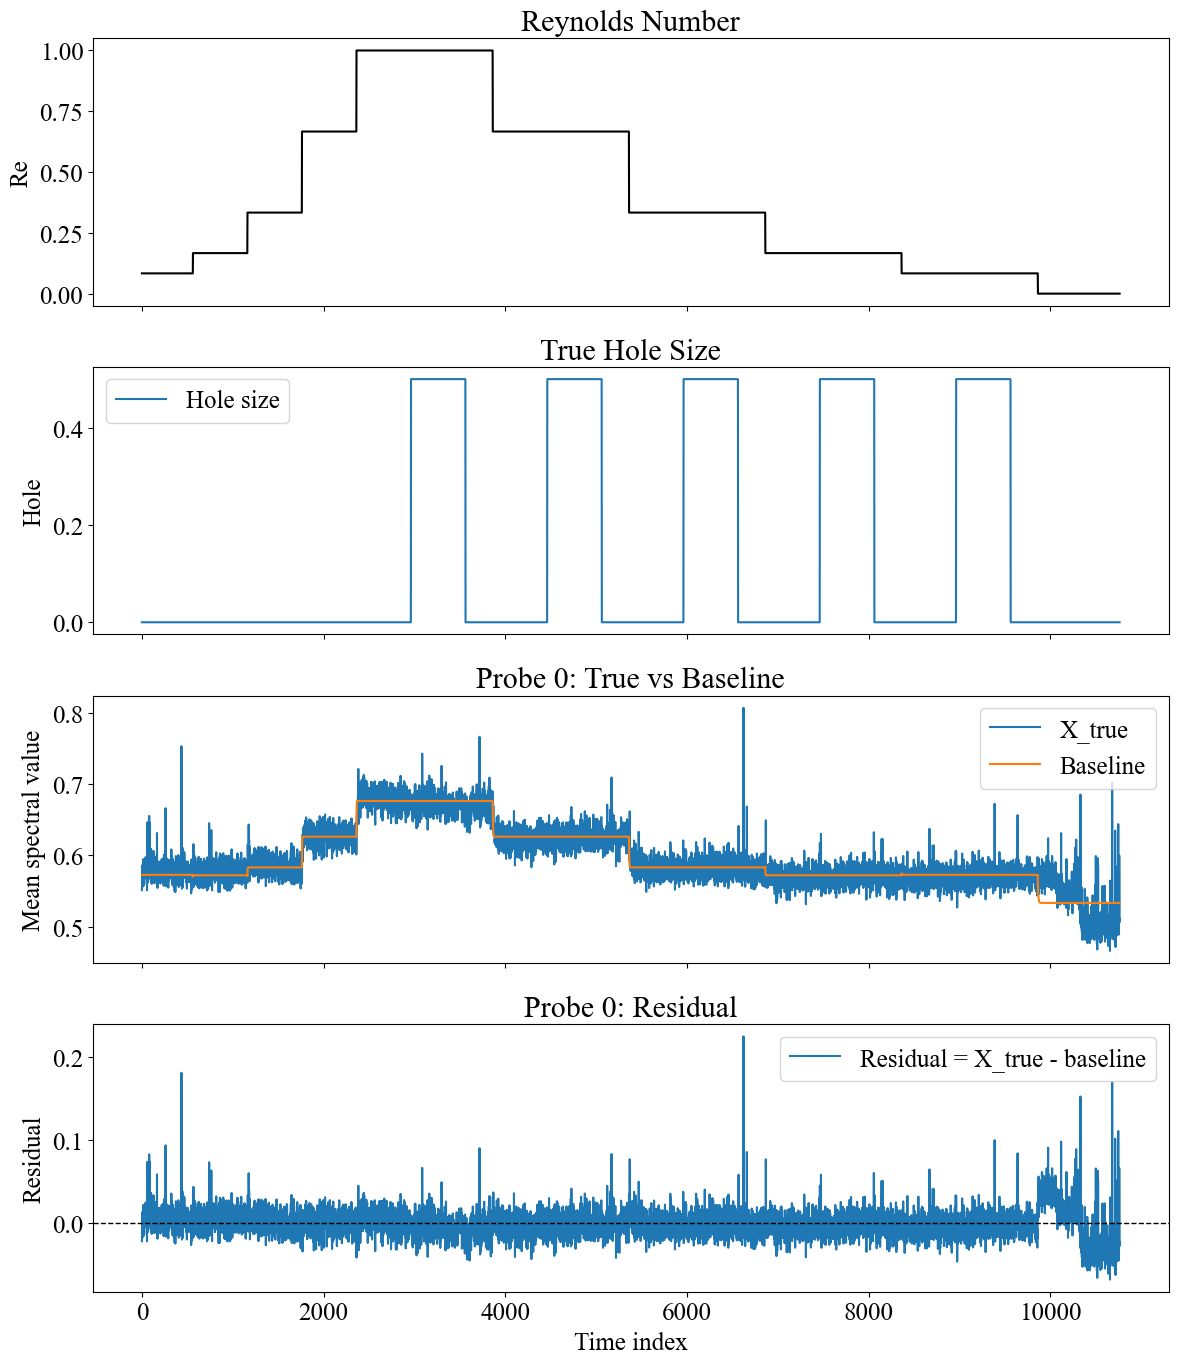

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simple plotting code for baseline model

def plot_baseline_diagnostics(result, probe_idx=0, freq_range=None):
    baseline = result["baseline"].numpy() 
    X_true   = result["X_true"].numpy()    
    Re       = result["Re"].numpy()
    hole     = result["hole"].numpy()

    residual = X_true - baseline

    if freq_range is None:
        freq_range = slice(None)

    p = probe_idx

    true_spec = X_true[:, p, freq_range]
    base_spec = baseline[:, p, freq_range]
    res_spec  = residual[:, p, freq_range]

    fig, axs = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

    # 1) Reynolds number
    axs[0].plot(Re, color="black")
    axs[0].set_ylabel("Re")
    axs[0].set_title("Reynolds Number")

    # 2) Leak / hole size
    axs[1].plot(hole, label="Hole size")
    axs[1].set_ylabel("Hole")
    axs[1].set_title("True Hole Size")
    axs[1].legend()

    # 3) True vs baseline
    axs[2].plot(true_spec.mean(axis=1), label="X_true")
    axs[2].plot(base_spec.mean(axis=1), label="Baseline")
    axs[2].set_ylabel("Mean spectral value")
    axs[2].set_title(f"Probe {p}: True vs Baseline")
    axs[2].legend()

    # 4) Residual
    axs[3].plot(res_spec.mean(axis=1), label="Residual = X_true - baseline")
    axs[3].axhline(0.0, color="black", linestyle="--", linewidth=1)
    axs[3].set_ylabel("Residual")
    axs[3].set_xlabel("Time index")
    axs[3].set_title(f"Probe {p}: Residual")
    axs[3].legend()

    plt.tight_layout()
    plt.show()


plot_baseline_diagnostics(
    baseline_results,
    probe_idx=0,
    freq_range=slice(14)
)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ProbeFrequencyUpdateBlock(nn.Module):
    def __init__(self, feat_dim, hidden_dim=64, dropout=0.1):
        super().__init__()
        self.feat_dim = feat_dim

        self.gate_mlp = nn.Sequential(
            nn.Linear(2 * feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

        self.out_dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(feat_dim)

    def forward(self, h_pre, return_stats=False):

        B_graph, P, D = h_pre.shape
        assert D == self.feat_dim, f"Expected feat_dim={self.feat_dim}, got {D}"

        hi = h_pre.unsqueeze(2).expand(B_graph, P, P, D)
        hj = h_pre.unsqueeze(1).expand(B_graph, P, P, D)

        diff = hj - hi
        abs_diff = torch.abs(diff)

        edge_feat = torch.cat([diff, abs_diff], dim=-1)
        gate = torch.sigmoid(self.gate_mlp(edge_feat))

        eye = torch.eye(P, device=h_pre.device).view(1, P, P, 1)
        gate = gate * (1.0 - eye)

        msg = diff * gate
        denom = gate.sum(dim=2).clamp_min(1e-6)
        agg = msg.sum(dim=2) / denom

        h_post = self.norm(self.out_dropout(agg))

        if return_stats:
            stats = {
                "gate_mean": gate.mean().detach(),
                "gate_matrix": gate.squeeze(-1).detach(),
                "agg_abs_mean": agg.abs().mean().detach(),
                "agg_norm": agg.norm(dim=-1).mean().detach(),
                "h_post_abs_mean": h_post.abs().mean().detach(),
                "h_post_norm": h_post.norm(dim=-1).mean().detach(),
            }
            return h_post, stats

        return h_post


class ResidualLSTMFrequencyGraphLeakNet(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        tf_hidden_dim=64,
        graph_hidden_dim=64,
        readout_hidden_dim=64,
        num_lstm_layers=1,
        dropout=0.1,
        weight_temperature=2.0,
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.weight_temperature = weight_temperature


        # Per-probe temporal encoder
        self.lstm = nn.LSTM(
            input_size=Freq,
            hidden_size=hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=0.0 if num_lstm_layers == 1 else dropout
        )

        # Decode hidden temporal features back into frequency space.
        self.decode_freq = nn.Sequential(
            nn.Linear(hidden_dim, tf_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(tf_hidden_dim, Freq)
        )

        self.summary_dim = 3 * Freq

        self.freq_block_dim = 3
        self.readout_block_dim = 6
        self.readout_dim = self.readout_block_dim * Freq 

        # Frequency-wise graph block
        self.gnn = ProbeFrequencyUpdateBlock(
            feat_dim=self.freq_block_dim,
            hidden_dim=graph_hidden_dim,
            dropout=dropout
        )

        # Probe-frequency score head
        self.probe_freq_score_head = nn.Sequential(
            nn.Linear(self.readout_block_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )


        # Optional diagnostic per-probe heads
        self.probe_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.probe_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        # Global heads
        self.global_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.global_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

    def _time_summary(self, x):

        x_mean = x.mean(dim=1)
        x_max = x.max(dim=1).values
        x_last = x[:, -1, :]

        return torch.cat([x_mean, x_max, x_last], dim=-1)

    def _reshape_summary_to_frequency_blocks(self, h_pre, B, P, Freq):
        h_pre_freq = h_pre.view(B, P, 3, Freq)
        h_pre_freq = h_pre_freq.permute(0, 1, 3, 2).contiguous()
        return h_pre_freq

    def _flatten_frequency_readout(self, h_readout_freq, B, P, Freq):

        h_readout = (
            h_readout_freq
            .permute(0, 1, 3, 2)    
            .contiguous()
            .view(B, P, 6 * Freq) 
        )
        return h_readout

    def _flatten_h_post_freq(self, h_post_freq, B, P, Freq):

        h_post = (
            h_post_freq
            .permute(0, 1, 3, 2)   
            .contiguous()
            .view(B, P, 3 * Freq)    
        )
        return h_post

    def _build_global_from_frequency_blocks(self, h_readout_freq):

        B, P, Freq, C = h_readout_freq.shape
        assert C == self.readout_block_dim, (
            f"Expected block dim={self.readout_block_dim}, got {C}"
        )

        # Score each probe-frequency block
        probe_freq_scores = self.probe_freq_score_head(h_readout_freq).squeeze(-1)

        # Independent sigmoid gates
        probe_freq_weights = torch.sigmoid(probe_freq_scores)

        # P-scaled weighted sum across probes
        h_global_freq = torch.sum(
            probe_freq_weights.unsqueeze(-1) * h_readout_freq,
            dim=1
        ) / P

        # Flatten back to (B, 6F)
        h_global = (
            h_global_freq
            .permute(0, 2, 1)
            .contiguous()
            .view(B, self.readout_block_dim * Freq)
        )

        # Diagnostic scalar per frequency
        h_global_scores = torch.sum(
            probe_freq_weights * probe_freq_scores,
            dim=1
        ) / P

        return (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        )

    def forward(
        self,
        residual_window,
        probe_coords=None,
        disable_gnn=False,
        return_gnn_stats=False,
    ):

        B, W, P, Freq = residual_window.shape
        assert Freq == self.Freq, f"Expected Freq={self.Freq}, got {Freq}"

        # Encode each probe independently through the LSTM
        x = residual_window.permute(0, 2, 1, 3).contiguous()
        x = x.view(B * P, W, Freq)

        lstm_out_raw, _ = self.lstm(x)    
        decoded_freq_raw = self.decode_freq(lstm_out_raw)  

        # Build mean / max / last time summary
        decoded_summary_raw = self._time_summary(decoded_freq_raw)
        h_pre = decoded_summary_raw.view(B, P, self.summary_dim)

        # Reshape into frequency-wise blocks
        h_pre_freq = self._reshape_summary_to_frequency_blocks(h_pre, B, P, Freq)

        # Graph each frequency across probes
        gnn_stats = None

        if not disable_gnn:
            h_for_gnn = h_pre_freq.permute(0, 2, 1, 3).contiguous()
            h_for_gnn = h_for_gnn.view(B * Freq, P, self.freq_block_dim)

            if return_gnn_stats:
                h_post_graph, gnn_stats = self.gnn(h_for_gnn, return_stats=True)
            else:
                h_post_graph = self.gnn(h_for_gnn)

            h_post_freq = h_post_graph.view(B, Freq, P, self.freq_block_dim)
            h_post_freq = h_post_freq.permute(0, 2, 1, 3).contiguous()
        else:
            h_post_freq = h_pre_freq

        # Flatten graph output for diagnostics
        h_post = self._flatten_h_post_freq(h_post_freq, B, P, Freq)

        # Build frequency-wise readout
        h_readout_freq = torch.cat([h_pre_freq, h_post_freq], dim=-1)

        # Flatten for optional diagnostic per-probe heads
        h_readout = self._flatten_frequency_readout(h_readout_freq, B, P, Freq)

        # Optional per-probe diagnostics
        probe_leak_logits = self.probe_leak_head(h_readout).squeeze(-1)
        probe_leak_probs = torch.sigmoid(probe_leak_logits)

        probe_mag_raw = self.probe_mag_head(h_readout).squeeze(-1)
        probe_mag_base = F.softplus(probe_mag_raw)

        # Build global vector from frequency-wise probe pooling
        (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        ) = self._build_global_from_frequency_blocks(h_readout_freq)

        # Global leak probability and magnitude
        leak_logit = self.global_leak_head(h_global).squeeze(-1)
        leak_prob = torch.sigmoid(leak_logit)

        mag_base = F.softplus(self.global_mag_head(h_global).squeeze(-1))

        magnitude = mag_base * leak_prob.detach()

        # Reshape LSTM outputs for diagnostics
        H = lstm_out_raw.shape[-1]

        lstm_out = (
            lstm_out_raw
            .view(B, P, W, H)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_freq = (
            decoded_freq_raw
            .view(B, P, W, Freq)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_summary = decoded_summary_raw.view(B, P, self.summary_dim)

        out = {
            # Final predictions
            "leak_logit": leak_logit,      # (B,)
            "leak_prob": leak_prob,        # (B,)
            "magnitude": magnitude,        # (B,)
            "mag_base": mag_base,          # (B,)

            # Main global representation
            "h_global": h_global,              # (B, 6F)
            "h_global_freq": h_global_freq,    # (B, F, 6)
            "h_global_scores": h_global_scores,# (B, F)

            # Frequency-wise graph / pooling diagnostics
            "h_pre_freq": h_pre_freq,                  # (B, P, F, 3)
            "h_post_freq": h_post_freq,                # (B, P, F, 3)
            "h_readout_freq": h_readout_freq,          # (B, P, F, 6)
            "probe_freq_scores": probe_freq_scores,    # (B, P, F)
            "probe_freq_weights": probe_freq_weights,  # (B, P, F)

            # Flattened diagnostics
            "h_pre": h_pre,                  # (B, P, 3F)
            "h_post": h_post,                # (B, P, 3F)
            "h_readout": h_readout,          # (B, P, 6F)

            # LSTM / decoded frequency diagnostics
            "lstm_out": lstm_out,                    # (B, W, P, H)
            "decoded_freq": decoded_freq,            # (B, W, P, F)
            "decoded_summary": decoded_summary,      # (B, P, 3F)

            # Optional per-probe diagnostic heads
            "probe_leak_logits": probe_leak_logits,  # (B, P)
            "probe_leak_probs": probe_leak_probs,    # (B, P)
            "probe_mag_base": probe_mag_base,        # (B, P)
        }

        if return_gnn_stats:
            out["gnn_stats"] = gnn_stats

        return out

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_fscore_support,
)
import numpy as np
import torch
import torch.nn as nn
import copy

import random


def apply_probe_dropout(Xw, coords, min_keep=2, drop_prob=0.7):
    B, W, P, F = Xw.shape

    # Sometimes keep all probes
    if random.random() > drop_prob or P <= min_keep:
        keep_idx = list(range(P))
        return Xw, coords, keep_idx

    keep_n = random.randint(min_keep, P)
    keep_idx = sorted(random.sample(range(P), keep_n))

    Xw_sub = Xw[:, :, keep_idx, :]
    coords_sub = coords[:, keep_idx, :]

    return Xw_sub, coords_sub, keep_idx

def permute_probes(Xw, coords):
    P = Xw.shape[2]
    perm = torch.randperm(P, device=Xw.device)

    Xw = Xw[:, :, perm, :]
    coords = coords[:, perm, :]

    return Xw, coords


def train_residual_lstm_leak_net(
    residual_model,
    baseline_model,
    train_loader,
    val_loader,
    epochs=100,
    lr=1e-3,
    cls_pos_weight=1.0,
    mag_weight=1.0,
    train_magnitude_on_all=False,
    threshold=0.3,
    tune_threshold=True,        
    threshold_grid=None,         
    early_stop_patience=20,       
    monitor="ap",               
    grad_clip_norm=None,      
    weight_decay=1e-4,
    device="cpu"
):
    residual_model.to(device)
    baseline_model.to(device)

    baseline_model.eval()
    for p in baseline_model.parameters():
        p.requires_grad = False

    optimizer = torch.optim.Adam(
        residual_model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )


    cls_criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([cls_pos_weight], device=device)
    )

    mag_criterion = nn.SmoothL1Loss(reduction="none")

    if threshold_grid is None:
        threshold_grid = np.linspace(0.05, 0.95, 91)

    best_metric = np.inf if monitor == "val_loss" else -np.inf
    best_state = None
    best_epoch = -1
    best_threshold = threshold
    epochs_no_improve = 0

    history = {
        "train_loss": [],
        "train_cls_loss": [],
        "train_mag_loss": [],
        "val_loss": [],
        "val_cls_loss": [],
        "val_mag_loss": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": [],
        "val_ap": [],
        "val_auc": [],
        "val_threshold": [],
        "lr": [],
    }

    for ep in range(epochs):
        # TRAIN
        residual_model.train()
        train_loss = 0.0
        train_cls_loss = 0.0
        train_mag_loss = 0.0

        for batch in train_loader:
            Xw = batch["window"].to(device).float()
            Rew = batch["Re_window"].to(device).float()
            coords = batch["coords"].to(device).float()
            y = batch["leak_label"].to(device).float().view(-1)
            hole = batch["hole_size"].to(device).float().view(-1)

            # Optional probe permutation first
            #Xw, coords = permute_probes(Xw, coords)

            # Probe dropout by subsetting probes
            Xw_sub, coords_sub, keep_idx = apply_probe_dropout(
                Xw, coords,
                min_keep=4,
                drop_prob=0
            )

            with torch.no_grad():
                baseline = baseline_model(Xw_sub, Rew, coords_sub)["baseline"]
                residual = Xw_sub - baseline

            out = residual_model(residual, coords_sub)

            leak_logit = out["leak_logit"].view(-1)
            mag = out["magnitude"].view(-1)

            leak_loss = cls_criterion(leak_logit, y)

            mag_loss_raw = mag_criterion(mag, hole)

            if train_magnitude_on_all:
                mag_loss = mag_loss_raw.mean()
            else:
                leak_mask = (y > 0).float()
                mag_loss = (mag_loss_raw * leak_mask).sum() / (leak_mask.sum() + 1e-8)

            loss = leak_loss + mag_weight * mag_loss

            optimizer.zero_grad()
            loss.backward()

            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(residual_model.parameters(), grad_clip_norm)

            optimizer.step()

            train_loss += loss.item()
            train_cls_loss += leak_loss.item()
            train_mag_loss += mag_loss.item()

        train_loss /= len(train_loader)
        train_cls_loss /= len(train_loader)
        train_mag_loss /= len(train_loader)

        # VALIDATION
        residual_model.eval()
        val_loss = 0.0
        val_cls_loss = 0.0
        val_mag_loss = 0.0

        all_probs = []
        all_labels = []

        with torch.no_grad():
            for batch in val_loader:
                Xw = batch["window"].to(device).float()
                Rew = batch["Re_window"].to(device).float()
                coords = batch["coords"].to(device).float()
                y = batch["leak_label"].to(device).float().view(-1)
                hole = batch["hole_size"].to(device).float().view(-1)

                baseline = baseline_model(Xw, Rew, coords)["baseline"]
                residual = Xw - baseline

                out = residual_model(residual, coords)

                leak_logit = out["leak_logit"].view(-1)
                mag = out["magnitude"].view(-1)

                leak_loss = cls_criterion(leak_logit, y)

                mag_loss_raw = mag_criterion(mag, hole)

                if train_magnitude_on_all:
                    mag_loss = mag_loss_raw.mean()
                else:
                    leak_mask = (y > 0).float()
                    mag_loss = (mag_loss_raw * leak_mask).sum() / (leak_mask.sum() + 1e-8)

                loss = leak_loss + mag_weight * mag_loss

                val_loss += loss.item()
                val_cls_loss += leak_loss.item()
                val_mag_loss += mag_loss.item()

                probs = torch.sigmoid(leak_logit)
                all_probs.append(probs.cpu())
                all_labels.append(y.cpu())

        val_loss /= len(val_loader)
        val_cls_loss /= len(val_loader)
        val_mag_loss /= len(val_loader)

        all_probs = torch.cat(all_probs).numpy()
        all_labels = torch.cat(all_labels).numpy()

        # Stable ranking metrics
        try:
            val_ap = average_precision_score(all_labels, all_probs)
        except Exception:
            val_ap = 0.0

        try:
            val_auc = roc_auc_score(all_labels, all_probs)
        except Exception:
            val_auc = float("nan")

        # Threshold selection
        if tune_threshold:
            best_f1_epoch = -1.0
            best_threshold_epoch = threshold
            best_precision_epoch = 0.0
            best_recall_epoch = 0.0

            for th in threshold_grid:
                preds_tmp = (all_probs > th).astype(float)
                p_tmp, r_tmp, f_tmp, _ = precision_recall_fscore_support(
                    all_labels,
                    preds_tmp,
                    average="binary",
                    zero_division=0
                )
                if f_tmp > best_f1_epoch:
                    best_f1_epoch = f_tmp
                    best_threshold_epoch = th
                    best_precision_epoch = p_tmp
                    best_recall_epoch = r_tmp

            val_threshold = float(best_threshold_epoch)
            val_precision = float(best_precision_epoch)
            val_recall = float(best_recall_epoch)
            val_f1 = float(best_f1_epoch)
        else:
            preds = (all_probs > threshold).astype(float)
            val_threshold = float(threshold)
            val_precision = precision_score(all_labels, preds, zero_division=0)
            val_recall = recall_score(all_labels, preds, zero_division=0)
            val_f1 = f1_score(all_labels, preds, zero_division=0)

        # Monitor metric
        if monitor == "ap":
            current_metric = val_ap
            improved = current_metric > best_metric
        elif monitor == "f1":
            current_metric = val_f1
            improved = current_metric > best_metric
        elif monitor == "val_loss":
            current_metric = val_loss
            improved = current_metric < best_metric
        else:
            raise ValueError("monitor must be one of: 'ap', 'f1', 'val_loss'")

        # Best checkpoint
        if improved:
            best_metric = current_metric
            best_state = copy.deepcopy(residual_model.state_dict())
            best_epoch = ep + 1
            best_threshold = val_threshold
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        # history
        history["train_loss"].append(train_loss)
        history["train_cls_loss"].append(train_cls_loss)
        history["train_mag_loss"].append(train_mag_loss)
        history["val_loss"].append(val_loss)
        history["val_cls_loss"].append(val_cls_loss)
        history["val_mag_loss"].append(val_mag_loss)
        history["val_precision"].append(val_precision)
        history["val_recall"].append(val_recall)
        history["val_f1"].append(val_f1)
        history["val_ap"].append(val_ap)
        history["val_auc"].append(val_auc)
        history["val_threshold"].append(val_threshold)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        print(f"\nEpoch {ep+1}/{epochs}")
        print(
            f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Cls: {train_cls_loss:.4f} | "
            f"Train Mag: {train_mag_loss:.4f}"
        )
        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Cls: {val_cls_loss:.4f} | "
            f"Val Mag: {val_mag_loss:.4f}"
        )
        print(
            f"Val Precision: {val_precision:.3f} | "
            f"Recall: {val_recall:.3f} | "
            f"F1: {val_f1:.3f} | "
            f"AP: {val_ap:.3f} | "
            f"AUC: {val_auc:.3f} | "
            f"Thresh: {val_threshold:.2f}"
        )
        print(
            f"Best Epoch: {best_epoch} | "
            f"Best {monitor}: {best_metric:.4f} | "
            f"No Improve: {epochs_no_improve}/{early_stop_patience}"
        )

        # early stop
        if epochs_no_improve >= early_stop_patience:
            print(f"\nEarly stopping triggered at epoch {ep+1}.")
            break

    # restore best model
    if best_state is not None:
        residual_model.load_state_dict(best_state)
        print(
            f"\nRestored best model from epoch {best_epoch} "
            f"with best {monitor} = {best_metric:.4f} "
            f"and threshold = {best_threshold:.2f}"
        )

    return residual_model, history, best_threshold

In [ ]:
train_windows = WindowedLeakDataset(train_dataset, window_size=40)
val_windows   = WindowedLeakDataset(val_dataset,   window_size=40)

train_loader = torch.utils.data.DataLoader(
    train_windows,
    batch_size=64,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    val_windows,
    batch_size=64,
    shuffle=False
)

residual_model = ResidualLSTMFrequencyGraphLeakNet(
    Freq=27,
        hidden_dim=64,
        tf_hidden_dim=64,
        graph_hidden_dim=64,
        readout_hidden_dim=64,
        num_lstm_layers=1,
        dropout=0.1,
).to(device)


# UNCOMMENT TO TRAIN LEAK DETECTION MDOEL

# residual_model, history, best_threshold = train_residual_lstm_leak_net(
#     residual_model=residual_model,
#     baseline_model=baseline_model,
#     train_loader=train_loader,
#     val_loader=val_loader,
#     epochs=5000,
#     lr=1e-3,
#     cls_pos_weight=1,
#     mag_weight=1,
#     train_magnitude_on_all=False,
#     threshold=0.05,
#     tune_threshold=True,
#     early_stop_patience=200,
#     monitor="ap",
#     grad_clip_norm=1.0,
#     device=device
# )

In [ ]:
# SAVE LEAK DETEDCTION MODEL... (change path to desired location)
#torch.save(residual_model.state_dict(), "/Users/eyeremy/Documents/GTvate_stuff/model_final/leak_detect_residual.pt")

# OR LOAD LEAK DETEDCTION MODEL (change path to where model is held)
state_dict = torch.load("/Users/eyeremy/Documents/GTvate_stuff/model_final/leak_detect_residual.pt", map_location=device)
residual_model.load_state_dict(state_dict)
residual_model = residual_model.to(device)

In [ ]:
import numpy as np
import torch


def run_sequence_inference(
    sequence_sample,
    baseline_model,
    residual_model,
    window_size=40,
    device="cpu",
    keep_probe_indices=None,
    drop_probe_indices=None,
    save_model_outputs=None,
    save_baseline_residual=True,
):

    baseline_model.eval()
    residual_model.eval()
    device = torch.device(device)

    if save_model_outputs is None:
        save_model_outputs = [
            "leak_prob",
            "magnitude",
            "mag_base",
            "h_global_scores",
            "probe_freq_weights",
        ]

    # Small helpers
    def to_tensor(x):
        if torch.is_tensor(x):
            return x.float()
        return torch.tensor(x, dtype=torch.float32)

    def select_probes(num_probes):
        if keep_probe_indices is not None and drop_probe_indices is not None:
            raise ValueError("Use either keep_probe_indices or drop_probe_indices, not both.")

        if keep_probe_indices is not None:
            idx = sorted(list(keep_probe_indices))
        elif drop_probe_indices is not None:
            idx = [i for i in range(num_probes) if i not in drop_probe_indices]
        else:
            idx = list(range(num_probes))

        if len(idx) == 0:
            raise ValueError("No probes left after probe selection.")

        return idx

    def get_re_window(Re_seq, t0, t1):
        if Re_seq.ndim == 0:
            return Re_seq.view(1, 1).repeat(1, window_size)

        if Re_seq.ndim == 1:
            return Re_seq[t0:t1].view(1, -1)

        return Re_seq[t0:t1].reshape(1, -1)

    def value_at_time(x, t):
        if x.ndim == 0:
            return float(x.item())
        return float(x[t].view(-1)[0].item())

    def save_output(results, name, value):
        if torch.is_tensor(value):
            value = value.detach().cpu()

            if value.ndim > 0 and value.shape[0] == 1:
                value = value[0]

            value = value.numpy()

        value = np.asarray(value)

        if value.ndim == 0:
            value = float(value)

        results[name].append(value)

    # Load sequence data
    X_seq = to_tensor(sequence_sample["X"])             # (T, P, F)
    coords = to_tensor(sequence_sample["coords"])       # (P, 2)
    Re_seq = to_tensor(sequence_sample["Re"])           # scalar or (T,)
    hole_seq = to_tensor(sequence_sample["hole"])       # (T,)
    leak_seq = to_tensor(sequence_sample["leak_open"])  # (T,)

    datetimes = sequence_sample["datetime"]
    iteration = sequence_sample.get("iteration", None)

    T, P_total, Freq = X_seq.shape

    if T < window_size:
        raise ValueError(f"T={T} is smaller than window_size={window_size}.")

    probe_idx = select_probes(P_total)

    X_seq = X_seq[:, probe_idx, :].to(device)
    coords = coords[probe_idx, :].to(device)
    Re_seq = Re_seq.to(device)
    hole_seq = hole_seq.to(device)
    leak_seq = leak_seq.to(device)

    coords_b = coords.unsqueeze(0)  # (1, P, 2)

    # Storage
    results = {
        "iteration": iteration,
        "used_probe_indices": probe_idx,
        "datetime": [],

        "true_label": [],
        "true_hole": [],
        "true_re": [],
    }

    for name in save_model_outputs:
        results[name] = []

    if save_baseline_residual:
        results["baseline_last"] = []
        results["residual_last"] = []

    # Inference loop
    with torch.no_grad():
        for t1 in range(window_size, T + 1):
            t0 = t1 - window_size
            t = t1 - 1

            Xw = X_seq[t0:t1].unsqueeze(0)       # (1, W, P, F)
            Rew = get_re_window(Re_seq, t0, t1)  # (1, W)

            baseline = baseline_model(Xw, Rew, coords_b)["baseline"]
            residual = Xw - baseline

            out = residual_model(residual, coords_b)

            results["datetime"].append(datetimes[t])
            results["true_label"].append(value_at_time(leak_seq, t))
            results["true_hole"].append(value_at_time(hole_seq, t))
            results["true_re"].append(value_at_time(Re_seq, t))

            for name in save_model_outputs:
                if name not in out:
                    raise KeyError(
                        f"'{name}' was requested in save_model_outputs, "
                        f"but it is not returned by residual_model."
                    )

                save_output(results, name, out[name])

            if save_baseline_residual:
                results["baseline_last"].append(
                    baseline[0, -1].detach().cpu().numpy()
                )
                results["residual_last"].append(
                    residual[0, -1].detach().cpu().numpy()
                )

    # Convert lists to arrays
    for key, value in list(results.items()):
        if isinstance(value, list):
            if key == "datetime":
                results[key] = np.asarray(value, dtype=object)
            else:
                results[key] = np.asarray(value)

    results["Freq"] = Freq
    results["num_probes"] = len(probe_idx)
    results["window_size"] = window_size

    return results

In [ ]:
# Run for validation data
result_val = run_sequence_inference(
    sequence_sample=val_dataset[0],
    baseline_model=baseline_model,
    residual_model=residual_model,
    window_size=40,
    device=device,
    save_model_outputs=[
        "leak_prob",
        "magnitude",
        "mag_base",
        "h_global_scores",
        "probe_freq_weights",
        "probe_freq_scores",
        "h_global_freq",
        "probe_leak_probs",
        "probe_mag_base",
    ],
)


# Run for testing data
result_test = run_sequence_inference(
    sequence_sample=test_dataset[0],
    baseline_model=baseline_model,
    residual_model=residual_model,
    window_size=40,
    device=device,
    save_model_outputs=[
        "leak_prob",
        "magnitude",
        "mag_base",
        "h_global_scores",
        "probe_freq_weights",
        "probe_freq_scores",
        "h_global_freq",
        "probe_leak_probs",
        "probe_mag_base",
    ],
)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Simple plotting code to look at results

def plot_leak_results(
    result,
    freq_values=None,
    plot_top_frequencies=6,
    plot_probe_weights=True,
):
    # x-axis
    x = pd.to_datetime(result["datetime"])

    # main outputs
    leak_prob = np.asarray(result.get("leak_prob", result.get("pred_prob")))
    magnitude = np.asarray(result.get("magnitude", result.get("pred_mag")))

    true_label = np.asarray(result["true_label"])
    true_hole = np.asarray(result["true_hole"])

    # diagnostics
    h_global_scores = np.asarray(result["h_global_scores"])          # (N, F)
    probe_freq_weights = np.asarray(result["probe_freq_weights"])    # (N, P, F)

    _, P, F = probe_freq_weights.shape

    if freq_values is None:
        freq_values = np.arange(F)

    used_probe_indices = result.get("used_probe_indices", list(range(P)))

    # 1. Leak probability
    plt.figure(figsize=(12, 4))
    plt.plot(x, leak_prob, label="Predicted leak probability")
    plt.plot(x, true_label, label="True leak state")
    plt.xlabel("Time")
    plt.ylabel("Leak probability")
    plt.title("Predicted Leak Probability")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 2. Leak magnitude
    plt.figure(figsize=(12, 4))
    plt.plot(x, magnitude, label="Predicted magnitude")
    plt.plot(x, true_hole, label="True hole size")
    plt.xlabel("Time")
    plt.ylabel("Magnitude / Hole size")
    plt.title("Predicted Leak Magnitude")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 3. Global frequency score heatmap
    plt.figure(figsize=(12, 5))
    plt.imshow(
        h_global_scores.T,
        aspect="auto",
        origin="lower",
        interpolation="nearest",
    )
    plt.colorbar(label="Global frequency score")
    plt.xlabel("Window index")
    plt.ylabel("Frequency index")
    plt.title("Global Frequency Scores Over Time")
    plt.tight_layout()
    plt.show()


    # 4. Top global frequency scores
    top_idx = np.argsort(np.abs(h_global_scores).mean(axis=0))[-plot_top_frequencies:][::-1]

    plt.figure(figsize=(12, 5))
    for f in top_idx:
        plt.plot(x, h_global_scores[:, f], label=f"{freq_values[f]} Hz")

    plt.plot(x, true_label, linestyle="--", label="True leak state")
    plt.xlabel("Time")
    plt.ylabel("Global frequency score")
    plt.title("Top Global Frequency Scores")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


    # 5. Probe-frequency weight heatmaps
    if plot_probe_weights:
        for p in range(P):
            probe_id = used_probe_indices[p]

            plt.figure(figsize=(12, 5))
            plt.imshow(
                probe_freq_weights[:, p, :].T,
                aspect="auto",
                origin="lower",
                interpolation="nearest",
            )
            plt.colorbar(label="Probe-frequency weight")
            plt.xlabel("Window index")
            plt.ylabel("Frequency index")
            plt.title(f"Probe-Frequency Weights Over Time: Probe {probe_id}")
            plt.tight_layout()
            plt.show()

In [ ]:
# Plot simple results

freq_values = [
    25, 31.5, 40, 50, 63, 80, 100, 125, 160,
    200, 250, 315, 400, 500, 630, 800, 1000, 1250,
    1600, 2000, 2500, 3100, 4000, 5000, 6300, 8000, 10000
]


plot_leak_results(
    result_val,
    freq_values=freq_values,
    plot_top_frequencies=6,
    plot_probe_weights=True,
)

plot_leak_results(
    result_test,
    freq_values=freq_values,
    plot_top_frequencies=6,
    plot_probe_weights=True,
)

In [ ]:
import numpy as np
import pandas as pd


def save_leak_results_csv(
    result,
    output_path="leak_results_simple.csv",
    freq_values=None,
):
    # Datetime with seconds
    datetime = pd.to_datetime(result["datetime"])
    datetime_str = pd.Series(datetime).dt.strftime("%Y-%m-%d %H:%M:%S")

    N = len(datetime_str)

    # Main scalar outputs
    pred_prob = np.asarray(result.get("pred_prob", result.get("leak_prob")))
    pred_mag = np.asarray(result.get("pred_mag", result.get("magnitude", np.full(N, np.nan))))

    true_label = np.asarray(result.get("true_label", np.full(N, np.nan)))
    true_hole = np.asarray(result.get("true_hole", np.full(N, np.nan)))
    true_re = np.asarray(result.get("true_re", np.full(N, np.nan)))

    # Model diagnostics
    h_global_scores = np.asarray(result["h_global_scores"])          # (N, F)
    probe_freq_weights = np.asarray(result["probe_freq_weights"])    # (N, P, F)

    _, P, F = probe_freq_weights.shape

    # Frequency labels
    if freq_values is None:
        freq_values = np.arange(F)
    else:
        freq_values = np.asarray(freq_values)

    used_probe_indices = result.get("used_probe_indices", list(range(P)))

    def clean_freq(freq):
        freq = float(freq)

        if freq.is_integer():
            return str(int(freq))

        return str(freq).replace(".", "_")

    # Main dataframe columns
    data = {
        "datetime": datetime_str,
        "pred_prob": pred_prob,
        "pred_mag": pred_mag,
        "true_label": true_label,
        "true_hole": true_hole,
        "true_re": true_re,
    }

    # Global frequency scores
    for f in range(F):
        freq_name = clean_freq(freq_values[f])
        data[f"global_score_{freq_name}Hz"] = h_global_scores[:, f]

    # Probe-frequency weights
    for p in range(P):
        probe_id = used_probe_indices[p]

        for f in range(F):
            freq_name = clean_freq(freq_values[f])
            data[f"probe_{probe_id}_weight_{freq_name}Hz"] = probe_freq_weights[:, p, f]

    df = pd.DataFrame(data)
    df.to_csv(output_path, index=False)

    print(f"Saved leak results to: {output_path}")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")

    return df

In [ ]:
# Save to csv: change 'results_val' to different inference data
# df = save_leak_results_csv(
#     result_val,
#     output_path="/Users/eyeremy/Documents/GTvate_stuff/1211_1_train_May4.csv",
#     freq_values=freq_values
# )